# Stream Processing with Apache Flink

Kafka stores and moves events (Lesson 02). **Stream processing** computes on them continuously: counts per minute,
joins of two streams, fraud rules, features for a model. **Apache Flink** is the leading open-source stream
processor. It keeps **state** (for example, the running count per zone), recovers it after failures with
**checkpoints**, and computes on **event time**, the time something happened, not the time the event arrived.

**After this lesson you can:**

1. Define a Kafka-backed table in Flink SQL and run continuous queries through the SQL Gateway REST API.
2. Explain event time, processing time and **watermarks**.
3. Compute tumbling-window aggregations and a window Top-N.
4. Measure the trade-off of the watermark delay: faster results vs. events dropped as late.

**Data:** NYC taxi trips of 2024-01-01 00:00–06:00, replayed in pickup order with 5 % of events arriving late.
**Services:** Kafka + Flink 1.20 (JobManager, TaskManager, SQL Gateway):
`docker compose -f docker/compose.yml --profile streaming --profile flink up -d kafka flink-jobmanager flink-taskmanager flink-sql-gateway`
(Flink UI on http://localhost:8082). The first start builds a small image that adds the Kafka connector.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from confluent_kafka import Consumer, Producer
from confluent_kafka.admin import AdminClient, NewTopic

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("streaming", "kafka")
for svc in ["flink-jobmanager", "flink-taskmanager", "flink-sql-gateway"]:
    datasets.ensure_service("flink", svc, timeout=600)       # the first start builds the image
GATEWAY, FLINK = "http://localhost:8084", "http://localhost:8082"
admin = AdminClient({"bootstrap.servers": "localhost:9092"})
print("Flink:", requests.get(f"{FLINK}/config", timeout=10).json()["flink-version"],
      "| task slots:", requests.get(f"{FLINK}/overview", timeout=10).json()["slots-total"])

def fresh_topic(name: str, partitions: int = 1) -> None:
    if name in admin.list_topics(timeout=10).topics:
        admin.delete_topics([name])[name].result()
        while name in admin.list_topics(timeout=10).topics:
            time.sleep(0.5)
    for _ in range(40):
        try:
            admin.create_topics([NewTopic(name, partitions, 1)])[name].result(); return
        except Exception:
            time.sleep(0.5)

Flink: 1.20.1 | task slots: 4


## 1. Event Time, Late Events and Watermarks

Events do not arrive in the order they happened: a phone is offline in a tunnel, a batch upload is delayed.
A window "10:00–10:10" can only be closed when the processor is reasonably sure no more events for it will come.
A **watermark** is Flink's estimate of event-time progress: *"no events older than W are expected any more"*.
With `WATERMARK FOR pickup_at AS pickup_at - INTERVAL '1' MINUTE`, the watermark trails the newest event by one
minute. When the watermark passes the end of a window, Flink emits the window and **drops later events for it**.
By default Flink advances the watermark every 200 ms of processing time, so the result of a replay depends on the read
speed; `'scan.watermark.emit.strategy' = 'on-event'` advances it after each event and makes this lesson repeatable.

The cell replays six hours of real trips. 5 % of them are delayed by 2–15 minutes of event time, so they appear in the
stream among newer events.

In [2]:
trips = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "total_amount"])
trips = trips[(trips.tpep_pickup_datetime >= "2024-01-01 00:00") & (trips.tpep_pickup_datetime < "2024-01-01 06:00")]
trips = trips.sort_values("tpep_pickup_datetime").reset_index(drop=True)
rng = np.random.default_rng(7)
late = rng.random(len(trips)) < 0.05
delay_min = np.where(late, rng.uniform(2, 15, len(trips)), 0.0)
trips["arrival_order"] = trips.tpep_pickup_datetime + pd.to_timedelta(delay_min, unit="min")   # position in the stream
trips["late"] = late
stream = trips.sort_values("arrival_order").reset_index(drop=True)

fresh_topic("rides")
p = Producer({"bootstrap.servers": "localhost:9092", "linger.ms": 20})
for r in stream.itertuples():
    p.produce("rides", json.dumps({"pickup_at": r.tpep_pickup_datetime.strftime("%Y-%m-%d %H:%M:%S"),
                                   "pu_zone": int(r.PULocationID), "total": float(r.total_amount)}))
    p.poll(0)
p.flush()
out_of_order = (stream.tpep_pickup_datetime.diff().dt.total_seconds() < 0).sum()
print(f"{len(stream):,} events, {late.sum():,} delayed by 2–15 min; {out_of_order:,} arrive after a newer event")

29,817 events, 1,452 delayed by 2–15 min; 1,409 arrive after a newer event


## 2. Talk to Flink through the SQL Gateway

The SQL Gateway accepts SQL statements over REST: open a **session**, submit a **statement**, fetch the **result**
pages. A `CREATE TABLE` with the Kafka connector does not copy data; it describes how to read the topic.

In [3]:
session = requests.post(f"{GATEWAY}/v1/sessions", json={"properties": {"execution.runtime-mode": "streaming"}},
                        timeout=30).json()["sessionHandle"]

def run_sql(statement: str, max_rows: int = 1000, timeout: float = 60) -> pd.DataFrame | None:
    """Submit one statement and collect its result rows (for INSERT jobs: the job id)."""
    op = requests.post(f"{GATEWAY}/v1/sessions/{session}/statements", json={"statement": statement},
                       timeout=30).json()["operationHandle"]
    uri, rows, cols, deadline = f"/v1/sessions/{session}/operations/{op}/result/0", [], None, time.time() + timeout
    while uri and time.time() < deadline and len(rows) < max_rows:
        res = requests.get(GATEWAY + uri, timeout=30).json()
        if "errors" in res:
            raise RuntimeError(res["errors"][-1][:600])
        if res.get("resultType") == "NOT_READY":
            time.sleep(0.5); continue
        cols = cols or [c["name"] for c in res["results"]["columns"]]
        rows += [d["fields"] for d in res["results"]["data"]]
        uri = res.get("nextResultUri") if res.get("resultType") != "EOS" else None
    requests.delete(f"{GATEWAY}/v1/sessions/{session}/operations/{op}/close", timeout=30)
    return pd.DataFrame(rows, columns=cols) if cols else None

def rides_table(name: str, watermark: str) -> None:
    run_sql(f"DROP TABLE IF EXISTS {name}")
    run_sql(f"""
    CREATE TABLE {name} (
        pickup_at TIMESTAMP(3),
        pu_zone INT,
        total DOUBLE,
        WATERMARK FOR pickup_at AS pickup_at - INTERVAL {watermark}
    ) WITH (
        'connector' = 'kafka', 'topic' = 'rides', 'properties.bootstrap.servers' = 'kafka:29092',
        'properties.group.id' = 'flink-{name}', 'scan.startup.mode' = 'earliest-offset',
        'format' = 'json', 'json.timestamp-format.standard' = 'SQL',
        'scan.watermark.emit.strategy' = 'on-event'   -- advance the watermark after every event (default: every 200 ms)
    )""")

rides_table("rides_wm1", "'1' MINUTE")
print(run_sql("SHOW TABLES").to_string(index=False))
print(run_sql("SELECT * FROM rides_wm1", max_rows=5, timeout=60).head(5).to_string(index=False))

table name
 rides_wm1


          pickup_at  pu_zone  total
2024-01-01T00:00:00      140  11.25
2024-01-01T00:00:02      161  16.32
2024-01-01T00:00:03      136   7.60
2024-01-01T00:00:04      125  38.80
2024-01-01T00:00:05      132  95.88


## 3. A Continuous Window Aggregation

`TUMBLE` splits event time into fixed, non-overlapping windows. The `INSERT INTO` starts a **streaming job** that
runs until it is cancelled: it reads the topic, keeps the counts per window and zone in state, and writes each window
to the output topic when the watermark closes it. The same job runs twice, with a 1-minute and a 20-minute watermark.

In [4]:
def window_job(tag: str, watermark: str) -> tuple[str, str]:
    src, sink = f"rides_{tag}", f"zone_counts_{tag}"
    rides_table(src, watermark)
    fresh_topic(sink)
    run_sql(f"DROP TABLE IF EXISTS {sink}")
    run_sql(f"""
    CREATE TABLE {sink} (window_start TIMESTAMP(3), window_end TIMESTAMP(3), pu_zone INT, trips BIGINT, revenue DOUBLE)
    WITH ('connector' = 'kafka', 'topic' = '{sink}', 'properties.bootstrap.servers' = 'kafka:29092',
          'format' = 'json', 'json.timestamp-format.standard' = 'SQL')""")
    job = run_sql(f"""
    INSERT INTO {sink}
    SELECT window_start, window_end, pu_zone, COUNT(*) AS trips, SUM(total) AS revenue
    FROM TABLE(TUMBLE(TABLE {src}, DESCRIPTOR(pickup_at), INTERVAL '10' MINUTES))
    GROUP BY window_start, window_end, pu_zone""")
    return job.iloc[0, 0], sink

def read_all(topic: str, quiet_s: float = 10) -> pd.DataFrame:
    c = Consumer({"bootstrap.servers": "localhost:9092", "group.id": f"nb-{time.time_ns()}", "auto.offset.reset": "earliest"})
    c.subscribe([topic])
    rows, last = [], time.time()
    while time.time() - last < quiet_s:
        msgs = c.consume(1000, timeout=1)
        if msgs:
            rows += [json.loads(m.value()) for m in msgs]; last = time.time()
    c.close()
    return pd.DataFrame(rows)

jobs = {}
for tag, wm in [("wm1", "'1' MINUTE"), ("wm20", "'20' MINUTE")]:
    jobs[tag] = window_job(tag, wm)
    print(tag, "job id:", jobs[tag][0])
time.sleep(5)
results = {tag: read_all(sink, quiet_s=15) for tag, (_, sink) in jobs.items()}
print(pd.DataFrame(requests.get(f"{FLINK}/jobs/overview", timeout=10).json()["jobs"])[["name", "state"]].to_string(index=False))

wm1 job id: 4f5f77e2dfd0399ea3c5d7158df12517


wm20 job id: a2e81c661c7923bea2efccafcdcaa6a2


                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         name    state
                                                                                                                                                                                                                                 

## 4. How Many Late Events Were Dropped?

The ground truth is a batch computation over **all** events with pandas. Windows that are still open at the end of
the stream (their end is after the last watermark) are left out of the comparison.

 watermark  windows emitted  events counted  events in those windows (truth)  dropped as late  dropped %
  1 minute               35           28122                            29111              989        3.4
20 minutes               33           29111                            29111                0        0.0


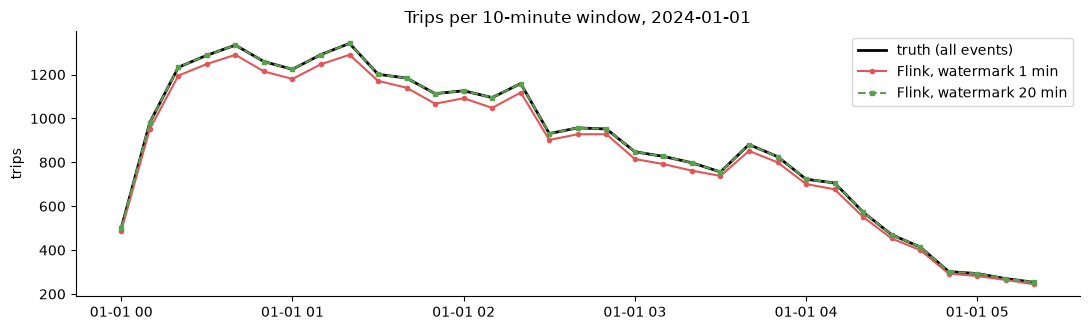

In [5]:
trips["window_start"] = trips.tpep_pickup_datetime.dt.floor("10min")
truth = trips.groupby("window_start").size().rename("truth")
rows = []
for tag, df in results.items():
    df["window_start"] = pd.to_datetime(df.window_start)
    got = df.groupby("window_start").trips.sum().rename(tag)
    rows.append(got)
cmp = pd.concat([truth] + rows, axis=1)
closed = cmp.dropna()                                  # windows emitted by both jobs
summary = pd.DataFrame({
    "watermark": ["1 minute", "20 minutes"],
    "windows emitted": [results["wm1"].window_start.nunique(), results["wm20"].window_start.nunique()],
    "events counted": [int(closed.wm1.sum()), int(closed.wm20.sum())],
    "events in those windows (truth)": [int(closed.truth.sum())] * 2,
})
summary["dropped as late"] = summary["events in those windows (truth)"] - summary["events counted"]
summary["dropped %"] = (100 * summary["dropped as late"] / summary["events in those windows (truth)"]).round(2)
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(closed.index, closed.truth, "k-", lw=2, label="truth (all events)")
ax.plot(closed.index, closed.wm1, "o-", color="#E15759", ms=3, label="Flink, watermark 1 min")
ax.plot(closed.index, closed.wm20, "s--", color="#59A14F", ms=3, label="Flink, watermark 20 min")
ax.set(title="Trips per 10-minute window, 2024-01-01", ylabel="trips"); ax.legend()
plt.tight_layout(); plt.show()

*Insight: The watermark delay is a business decision: a short delay gives results sooner but drops late events; a long delay is complete but every window is published later. Not every delayed event was dropped (989 of 1,452 with the 1-minute watermark): an event is late only if the watermark has already closed *its* window (a pickup at 10:03 delayed by 5 minutes still lands in the open 10:00–10:10 window). Flink can also send late events to a side output or update results ("allowed lateness") instead of dropping them.*

## 5. Window Top-N: the Busiest Zones per Window

Flink SQL supports Top-N per window with `ROW_NUMBER()` over the window columns. This is a typical real-time
dashboard query.

In [6]:
top = run_sql("""
SELECT window_start, pu_zone, trips, rn FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY window_start, window_end ORDER BY trips DESC) AS rn
  FROM (SELECT window_start, window_end, pu_zone, COUNT(*) AS trips
        FROM TABLE(TUMBLE(TABLE rides_wm20, DESCRIPTOR(pickup_at), INTERVAL '60' MINUTES))
        GROUP BY window_start, window_end, pu_zone))
WHERE rn <= 3""", max_rows=15, timeout=90)
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv")).set_index("LocationID").Zone
top["zone"] = top.pu_zone.map(zones)
print(top.sort_values(["window_start", "rn"]).to_string(index=False))

       window_start  pu_zone  trips  rn                  zone
2024-01-01T00:00:00       79    354   1          East Village
2024-01-01T00:00:00      237    290   2 Upper East Side South
2024-01-01T00:00:00      142    266   3   Lincoln Square East
2024-01-01T01:00:00       79    395   1          East Village
2024-01-01T01:00:00      263    288   2        Yorkville West
2024-01-01T01:00:00      170    271   3           Murray Hill
2024-01-01T02:00:00       79    476   1          East Village
2024-01-01T02:00:00      107    310   2              Gramercy
2024-01-01T02:00:00      148    248   3       Lower East Side
2024-01-01T03:00:00       79    484   1          East Village
2024-01-01T03:00:00      148    285   2       Lower East Side
2024-01-01T03:00:00       48    259   3          Clinton East
2024-01-01T04:00:00       79    298   1          East Village
2024-01-01T04:00:00       48    239   2          Clinton East
2024-01-01T04:00:00      148    174   3       Lower East Side


## 6. State, Checkpoints and Clean-Up

The window counts live in Flink **state** (in memory here; RocksDB on disk for large state). With checkpointing on,
Flink periodically snapshots all state and the Kafka offsets together; after a crash it restores both, so every
event is counted exactly once. The cell lists the running jobs, then cancels them.

In [7]:
for j in requests.get(f"{FLINK}/jobs/overview", timeout=10).json()["jobs"]:
    if j["state"] == "RUNNING":
        detail = requests.get(f"{FLINK}/jobs/{j['jid']}", timeout=10).json()
        print(f"{j['name'].split('.')[-1]:<20} vertices: {len(detail['vertices'])}, running for {j['duration'] / 1000:.0f} s")
        requests.patch(f"{FLINK}/jobs/{j['jid']}?mode=cancel", timeout=10)
time.sleep(3)
print("states now:", [j["state"] for j in requests.get(f"{FLINK}/jobs/overview", timeout=10).json()["jobs"]])
requests.delete(f"{GATEWAY}/v1/sessions/{session}", timeout=10);

zone_counts_wm1      vertices: 2, running for 52 s
zone_counts_wm20     vertices: 2, running for 45 s


states now: ['CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED', 'CANCELED']


| Engine | Model | Typical use |
| :--- | :--- | :--- |
| Apache Flink | true streaming, event time, large state | fraud detection, real-time features, CDC pipelines |
| Spark Structured Streaming (M13) | micro-batches | teams already on Spark, minute-level latency |
| Kafka Streams | library inside a Java service | per-service stream logic |
| RisingWave / Materialize | streaming databases (SQL views) | incrementally updated dashboards |

## Real-World Use Case or Analogy

A watermark is like the **closing time of a polling station**: votes are counted per station after it closes; a
voter who arrives after closing is not counted. Closing later counts more votes, but the result comes later.

Ride-hailing and food-delivery companies run Flink jobs on trip and order events to compute supply and demand per
area every minute; surge pricing and courier dispatch read those windows within seconds.